# The numbers behind the decks
**TikTok Shop Southeast Asia Regional Case Challenge 2026 · Vietnam, Malaysia, Thailand**
Rachel Tran · [case study](../README.md)

Each of our three solution decks ends with an appendix that traces every figure to the case, to our own arithmetic or to an assumption. This notebook turns those appendices into code:

1. **Rebuild** each headline number from the case exhibits.
2. **Check** it against the figure printed in the deck, within rounding.
3. **Stress-test** the assumption each plan leans on hardest.

> All case figures are **fictional**, supplied by the organisers for the competition, and only the inputs our decks cite are reproduced here. The three stress tests (sections 1.3, 2.3 and 3.4) were added after submission.

Labels follow the decks: **C** = case data · **D** = our arithmetic · **M** = our assumption or team rule.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from chart_style import new_chart, note, hbar, text_after, save, BLUE, ORANGE, GRAY, INK, INK2, SURFACE

AUDIT = []

def show_num(v):
    a = abs(v)
    return f"{v:,.0f}" if a >= 1000 else f"{v:,.1f}" if a >= 10 else f"{v:,.2f}" if a >= 1 else f"{v:.3f}"

def check(market, figure, deck, computed, tol):
    """Compare a recomputed figure with the value printed in the deck (tol = allowed rounding)."""
    ok = abs(computed - deck) <= tol
    AUDIT.append({"market": market, "figure": figure, "deck": deck, "recomputed": round(computed, 4),
                  "match": "yes" if ok else "NO"})
    print(f"{'✓' if ok else '✗'} {figure:<46} deck {show_num(deck):>8}   recomputed {show_num(computed):>8}")

## 1 · Vietnam: one creator, one day, US$1M on 12.12

**The brief.** Build one emerging creator into a US$1M GMV livestream on 12 December through strategy and operations, not aggressive subsidy.
**Our answer.** Pick the only creator who can physically reach US$1M in a day, find the one driver that has to move, then run the day against a fixed hourly bar with pre-agreed responses (the *Tích Tắc 12.12* Mission Control tool).

### 1.1 Who can reach US$1M inside one day? `C → D`

In [2]:
# Case Table 1: peak livestream session in the last 3 months [C]
creators = pd.DataFrame({
    "creator":        ["A", "B", "C", "D", "E"],
    "profile":        ["Celebrity", "Entertainment", "Entertainment", "Industry expert", "Industry expert"],
    "peak_gmv_usd":   [533_204, 575_976, 516_641, 554_234, 509_257],
    "gph_usd":        [27_751, 67_782, 13_771, 25_967, 33_263],      # GMV per live hour
    "live_hours":     [19.2, 8.5, 37.5, 21.3, 15.3],
    "total_views":    [54_227_321, 44_059_606, 67_420_561, 10_951_626, 64_747_462],
    "views_per_hour": [2_822_278, 5_185_008, 1_797_096, 513_112, 4_229_096],
}).set_index("creator")

# Case Table 3: top-3 categories as (category, share of GMV) [C]
mix = {
    "A": [("Fashion", .679), ("Lifestyle", .147), ("Grocery", .115)],
    "B": [("Health & Beauty", .607), ("Fashion", .376), ("Electronics", .011)],
    "C": [("Health & Beauty", .694), ("Electronics", .306), ("Grocery", .001)],
    "D": [("Electronics", .905), ("Health & Beauty", .094), ("Grocery", .001)],
    "E": [("Mom & Babies", .604), ("Health & Beauty", .388), ("Grocery", .0)],
}
# Case Table 4: December GMV index by category. The case masks the data, so these are read off its chart [C]
dec_index = {"Fashion": 1.48, "Health & Beauty": 1.39, "Mom & Babies": 1.27,
             "Lifestyle": 1.18, "Grocery": 1.14, "Electronics": 1.13}

TARGET = 1_000_000
creators["hours_to_1m"] = TARGET / creators["gph_usd"]                                   # [D]
creators["fits_in_one_day"] = creators["hours_to_1m"] <= 24
creators["december_fit"] = [sum(s * dec_index[c] for c, s in mix[k]) / sum(s for _, s in mix[k])
                            for k in creators.index]                                       # [D]
display(creators[["profile", "gph_usd", "views_per_hour", "hours_to_1m", "fits_in_one_day", "december_fit"]].round(2))

for k, deck in zip("ABCDE", [36.0, 14.8, 72.6, 38.5, 30.1]):
    check("Vietnam", f"Hours to US$1M, Creator {k}", deck, creators.loc[k, "hours_to_1m"], 0.05)
for k, deck in zip("ABCDE", [1.39, 1.42, 1.31, 1.15, 1.32]):
    check("Vietnam", f"December demand fit, Creator {k}", deck, creators.loc[k, "december_fit"], 0.005)

✓ Hours to US$1M, Creator A                      deck     36.0   recomputed     36.0
✓ Hours to US$1M, Creator B                      deck     14.8   recomputed     14.8
✓ Hours to US$1M, Creator C                      deck     72.6   recomputed     72.6
✓ Hours to US$1M, Creator D                      deck     38.5   recomputed     38.5
✓ Hours to US$1M, Creator E                      deck     30.1   recomputed     30.1
✓ December demand fit, Creator A                 deck     1.39   recomputed     1.39
✓ December demand fit, Creator B                 deck     1.42   recomputed     1.42
✓ December demand fit, Creator C                 deck     1.31   recomputed     1.31
✓ December demand fit, Creator D                 deck     1.15   recomputed     1.15
✓ December demand fit, Creator E                 deck     1.32   recomputed     1.32


,profile,gph_usd,views_per_hour,hours_to_1m,fits_in_one_day,december_fit
creator,,,,,,
A,Celebrity,27751,2822278,36.03,False,1.39
B,Entertainment,67782,5185008,14.75,True,1.42
C,Entertainment,13771,1797096,72.62,False,1.31
D,Industry expert,25967,513112,38.51,False,1.15
E,Industry expert,33263,4229096,30.06,False,1.32


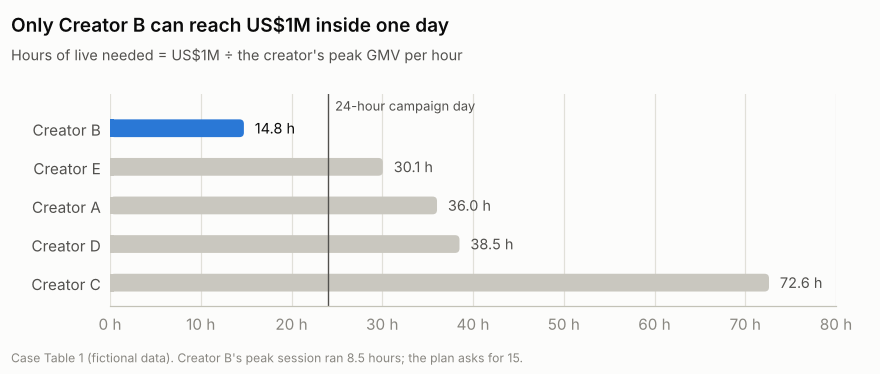

In [3]:
rank = creators["hours_to_1m"].sort_values()                    # Creator B first
fig, ax = new_chart("Only Creator B can reach US$1M inside one day",
                    "Hours of live needed = US$1M ÷ the creator's peak GMV per hour",
                    height=3.4, left=1.0, bottom=0.62)
ax.set_xlim(0, 80); ax.set_ylim(-0.6, len(rank) - 0.1)
ax.xaxis.grid(True); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
for i, (k, h) in enumerate(rank.items()):
    y = len(rank) - 1 - i
    hbar(ax, y, h, height=0.46, color=BLUE if k == "B" else GRAY)
    ax.text(h + 1.2, y, f"{h:.1f} h", va="center", fontsize=9.5, color=INK if k == "B" else INK2)
ax.set_yticks(range(len(rank)), [f"Creator {k}" for k in rank.index[::-1]])
ax.tick_params(axis="y", colors=INK2)
ax.axvline(24, color=INK2, lw=0.9)
ax.text(24.8, len(rank) - 0.42, "24-hour campaign day", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f} h")
note(fig, "Case Table 1 (fictional data). Creator B's peak session ran 8.5 hours; the plan asks for 15.")
save(fig, "vn_hours_to_1m"); plt.show()

Creator B needs 14.8 hours; the other four need 30 to 73. B's peak hour (US$67.8K) is twice the next best, and 98% of B's sales sit in Health & Beauty and Fashion, the two strongest December categories (demand fit 1.42, the highest of the five). The catch is duration: that peak session lasted 8.5 hours, so the plan has to hold it for 15.

### 1.2 The driver tree and the hourly pass mark `C → D`

GMV = views × (orders per 1,000 views) × AOV ÷ 1,000. Holding conversion and order value at Creator B's peak, the lever that has to move is views, and it moves through hours: 15 hours at about 98% of the peak views per hour.

In [4]:
b = creators.loc["B"]
gpm = b["peak_gmv_usd"] / b["total_views"] * 1000                  # GMV per 1,000 views [D]
b_mix = [(.607, 9.90), (.376, 11.10), (.011, 7.30)]                # (GMV share, AOV in US$), Table 3 [C]
aov = sum(s for s, _ in b_mix) / sum(s / a for s, a in b_mix)       # order-weighted AOV [D]
conv = gpm / aov                                                    # orders per 1,000 views [D]

def gmv(views, conv, aov):
    return views * conv * aov / 1000

views_plan_h = round(0.98 * b["views_per_hour"], -5)   # 98% of peak views per hour = 5.1M [M]
HOURS = 15                                              # 08:00-23:00; 14.8 h rounded up [M]
today = gmv(44.1e6, 1.27, 10.3)                         # the deck's rounded drivers
plan = gmv(views_plan_h * HOURS, 1.27, 10.3)
pass_mark = TARGET / HOURS
driver_hour = gmv(views_plan_h, 1.27, 10.30)

print(f"GMV per 1,000 views {gpm:.2f} · order-weighted AOV ${aov:.2f} · orders per 1,000 views {conv:.3f}")
print(f"Best session today: 44.1M views -> ${today:,.0f}")
print(f"Plan: {HOURS} h x {views_plan_h/1e6:.1f}M views/h = {views_plan_h*HOURS/1e6:.1f}M views -> ${plan:,.0f}")
print(f"Hourly pass mark ${pass_mark:,.0f}; the three driver targets multiply to ${driver_hour:,.0f} an hour\n")

check("Vietnam", "Orders per 1,000 views (conversion)", 1.27, conv, 0.005)
check("Vietnam", "Order-weighted AOV (US$)", 10.3, aov, 0.05)
check("Vietnam", "GMV at the best session (US$M)", 0.58, today / 1e6, 0.005)
check("Vietnam", "GMV at plan views (US$M)", 1.00, plan / 1e6, 0.005)
check("Vietnam", "Views gap to close (%)", 74, (views_plan_h * HOURS / b["total_views"] - 1) * 100, 0.6)
check("Vietnam", "Hourly pass mark (US$)", 66_667, pass_mark, 1)
check("Vietnam", "Go/no-go gate on 11.11 GPH (US$K)", 68, b["gph_usd"] / 1000, 0.3)

GMV per 1,000 views 13.07 · order-weighted AOV $10.28 · orders per 1,000 views 1.272
Best session today: 44.1M views -> $576,872
Plan: 15 h x 5.1M views/h = 76.5M views -> $1,000,697
Hourly pass mark $66,667; the three driver targets multiply to $66,713 an hour

✓ Orders per 1,000 views (conversion)            deck     1.27   recomputed     1.27
✓ Order-weighted AOV (US$)                       deck     10.3   recomputed     10.3
✓ GMV at the best session (US$M)                 deck    0.580   recomputed    0.577
✓ GMV at plan views (US$M)                       deck     1.00   recomputed     1.00
✓ Views gap to close (%)                         deck     74.0   recomputed     73.6
✓ Hourly pass mark (US$)                         deck   66,667   recomputed   66,667
✓ Go/no-go gate on 11.11 GPH (US$K)              deck     68.0   recomputed     67.8


Mission Control tests each completed hour against that one fixed bar (US$66,667), shows *Watch* after one miss and *Act now* after two in a row, and splits the hour into the three drivers so the weakest one gets its pre-agreed action and owner.

### 1.3 Stress test (post-submission): what if GMV fades during the day? `M`

The pass mark is a straight line: every hour must make the same US$66.7K. But a 15-hour live is almost twice Creator B's longest peak, and audiences and hosts tire. Here each hour sells a fixed percentage less than the one before, and the deck's shift resets (08:00, 13:00 and 18:00: fresh hero deal, ad top-up, co-host swap) restore the opening level.

In [5]:
OPEN = driver_hour                   # first hour at the plan's driver targets, about $66.7K [M]
SHIFTS, SHIFT_H = 3, 5               # deck run of show: resets at 08:00, 13:00 and 18:00 [M]

def day_gmv(fade, resets=True, open_hour=OPEN):
    if resets:
        return SHIFTS * sum(open_hour * (1 - fade) ** h for h in range(SHIFT_H))
    return sum(open_hour * (1 - fade) ** h for h in range(SHIFTS * SHIFT_H))

fades = [i / 100 for i in range(0, 7)]
stress = pd.DataFrame({
    "hourly_fade": [f"{f:.0%}" for f in fades],
    "gmv_with_resets": [day_gmv(f) for f in fades],
    "gmv_one_long_session": [day_gmv(f, resets=False) for f in fades],
    "opening_hour_needed_with_resets": [TARGET * OPEN / day_gmv(f) for f in fades],
}).set_index("hourly_fade")
display(stress.round(0))

,gmv_with_resets,gmv_one_long_session,opening_hour_needed_with_resets
hourly_fade,,,
0%,1000696.0,1000696.0,66667.0
1%,980882.0,933594.0,68013.0
2%,961461.0,872043.0,69387.0
3%,942429.0,815565.0,70788.0
4%,923779.0,763721.0,72218.0
5%,905506.0,716110.0,73675.0
6%,887604.0,672366.0,75161.0


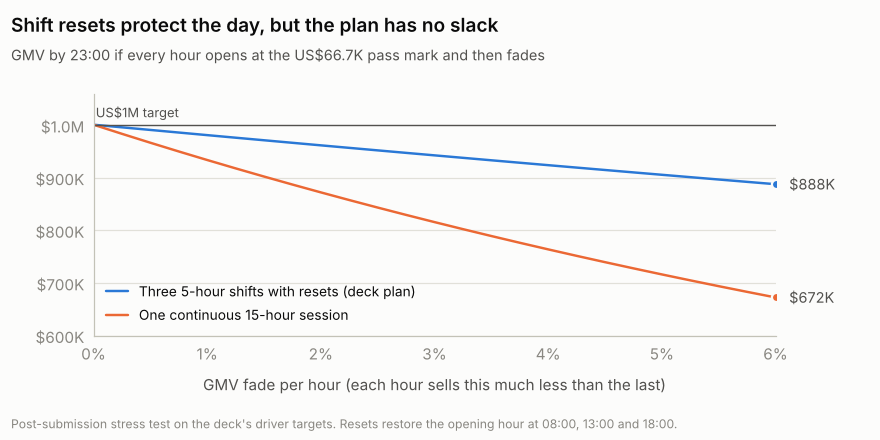

In [6]:
xs = [i / 400 for i in range(0, 25)]                   # 0% to 6% in quarter-point steps
fig, ax = new_chart("Shift resets protect the day, but the plan has no slack",
                    "GMV by 23:00 if every hour opens at the US$66.7K pass mark and then fades",
                    height=4.0, left=0.85, right=0.95, bottom=0.95)
ax.set_xlim(0, 0.06); ax.set_ylim(600_000, 1_060_000)
ax.yaxis.grid(True); ax.set_axisbelow(True)
for resets, color, label in [(True, BLUE, "Three 5-hour shifts with resets (deck plan)"),
                             (False, ORANGE, "One continuous 15-hour session")]:
    ys = [day_gmv(f, resets) for f in xs]
    ax.plot(xs, ys, color=color, lw=1.6, solid_capstyle="round", label=label)
    ax.plot(xs[-1], ys[-1], "o", ms=6, color=color, mec=SURFACE, mew=1.5)
    ax.text(xs[-1] + 0.0012, ys[-1], f"${ys[-1]/1e3:,.0f}K", va="center", fontsize=9.5, color=INK2)
ax.axhline(TARGET, color=INK2, lw=0.9)
ax.text(0.0002, TARGET + 9_000, "US$1M target", fontsize=8.5, color=INK2, va="bottom")
ax.legend(loc="lower left", fontsize=9, handlelength=1.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"${v/1e6:.1f}M" if v >= 1e6 else f"${v/1e3:,.0f}K")
ax.set_xlabel("GMV fade per hour (each hour sells this much less than the last)", labelpad=8)
note(fig, "Post-submission stress test on the deck's driver targets. Resets restore the opening hour at 08:00, 13:00 and 18:00.")
save(fig, "vn_fade_stress"); plt.show()

At a 2% fade per hour, three shifts with resets land at **US$961K** (-3.9%), while one unbroken session lands at **US$872K** (-12.8%): the resets recover about two-thirds of the loss. But at any fade the plan misses, and to still reach US$1M at a 3% fade the opening hour must sell **US$70.8K**, above Creator B's best-ever hour of US$67.8K.

What this changes: the 11.11 rehearsal should record the real hour-by-hour shape so the 12.12 pass mark can follow it (higher early, lower late) instead of a straight line, and the go/no-go gate should test the rehearsal's *late* hours, not only its average.

## 2 · Malaysia: winning the Malaysian wallet

**The brief.** Win a larger share of Malaysian online spend over 12 months, with headcount for only one segment pilot, and make subsidy work harder than blanket discounts.
**Our answer.** Growth is not a reach problem but a frequency-and-trust problem. Pilot parents aged 41+, reached through their children (the *Order Pertama Mak* journey), and let a three-arm test decide whether to scale.

### 2.1 Where growth leaks `C → D`

In [7]:
# Exhibit 1: three-year trajectory [C]
traj = pd.DataFrame({"buyers_m": [4.5, 5.3, 6.2], "orders_m": [205, 280, 360], "gmv_rm_bn": [5.33, 7.46, 9.70]},
                    index=[2024, 2025, 2026])
traj["orders_per_buyer"] = traj["orders_m"] / traj["buyers_m"]
traj["orders_per_buyer_growth"] = traj["orders_per_buyer"].pct_change()
traj["gmv_growth"] = traj["gmv_rm_bn"].pct_change()
display(traj.round(3))

check("Malaysia", "GMV growth 2026 (%)", 30, traj.loc[2026, "gmv_growth"] * 100, 0.5)
check("Malaysia", "Orders-per-buyer growth 2025 (%)", 15.9, traj.loc[2025, "orders_per_buyer_growth"] * 100, 0.15)
check("Malaysia", "Orders-per-buyer growth 2026 (%)", 9.9, traj.loc[2026, "orders_per_buyer_growth"] * 100, 0.15)

✓ GMV growth 2026 (%)                            deck     30.0   recomputed     30.0
✓ Orders-per-buyer growth 2025 (%)               deck     15.9   recomputed     16.0
✓ Orders-per-buyer growth 2026 (%)               deck     9.90   recomputed     9.91


,buyers_m,orders_m,gmv_rm_bn,orders_per_buyer,orders_per_buyer_growth,gmv_growth
2024,4.5,205,5.33,45.556,NaN,NaN
2025,5.3,280,7.46,52.830,0.160,0.4
2026,6.2,360,9.70,58.065,0.099,0.3


In [8]:
# Exhibit 5: tracked new-buyer funnel, Q3 2026 (unique users, from clicks onward) [C]
funnel = pd.Series({"Clicked into shop or product": 9.5, "Viewed a product page": 7.4, "Added to cart": 2.5,
                    "Started checkout": 1.5, "Completed first order": 0.87}, name="users_m")
display(pd.DataFrame({"users_m": funnel, "share_of_previous_step": funnel / funnel.shift(1)}).round(3))

check("Malaysia", "Product viewers who add to cart (%)", 34,
      funnel["Added to cart"] / funnel["Viewed a product page"] * 100, 0.5)
check("Malaysia", "Checkouts left unfinished (%)", 42,
      (1 - funnel["Completed first order"] / funnel["Started checkout"]) * 100, 0.5)

✓ Product viewers who add to cart (%)            deck     34.0   recomputed     33.8
✓ Checkouts left unfinished (%)                  deck     42.0   recomputed     42.0


,users_m,share_of_previous_step
Clicked into shop or product,9.50,NaN
Viewed a product page,7.40,0.779
Added to cart,2.50,0.338
Started checkout,1.50,0.600
Completed first order,0.87,0.580


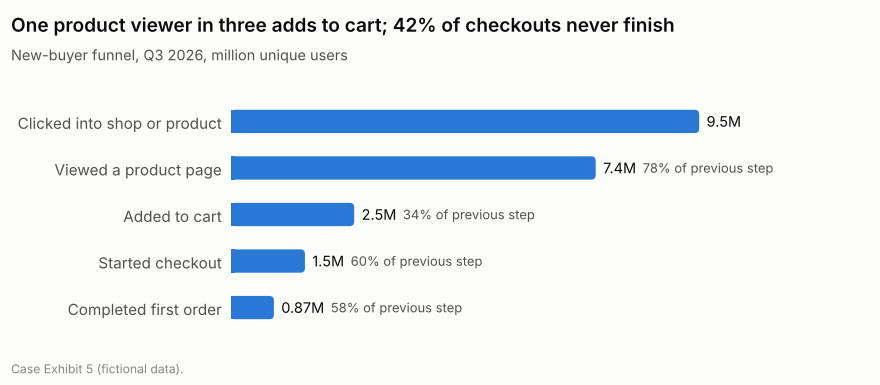

In [9]:
fig, ax = new_chart("One product viewer in three adds to cart; 42% of checkouts never finish",
                    "New-buyer funnel, Q3 2026, million unique users", height=3.5, left=2.1, right=0.3, bottom=0.45)
ax.set_xlim(0, 12.5); ax.set_ylim(-0.6, len(funnel) - 0.4)
ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False); ax.set_xticks([])
prev = None
for i, (stage, users) in enumerate(funnel.items()):
    y = len(funnel) - 1 - i
    hbar(ax, y, users, height=0.5, color=BLUE)
    value = ax.text(users + 0.15, y, f"{users:g}M", va="center", fontsize=9.5, color=INK)
    if prev is not None:
        text_after(ax, value, f"{users / prev:.0%} of previous step", fontsize=8.5, color=INK2)
    prev = users
ax.set_yticks(range(len(funnel)), list(funnel.index[::-1]))
ax.tick_params(axis="y", colors=INK2)
note(fig, "Case Exhibit 5 (fictional data).")
save(fig, "my_funnel"); plt.show()

In [10]:
# Exhibit 5: first-order attribution by channel [C]
ch = pd.DataFrame({"new_buyers_m": [0.55, 0.32], "cost_per_buyer_rm": [15, 31], "repeat_90d": [0.49, 0.19]},
                  index=["Content-led", "Campaign-led"])
ch["spend_rm_m"] = ch["new_buyers_m"] * ch["cost_per_buyer_rm"]
ch["repeat_buyers_m"] = ch["new_buyers_m"] * ch["repeat_90d"]
ch["cost_per_repeat_buyer_rm"] = ch["cost_per_buyer_rm"] / ch["repeat_90d"]
ch["share_of_spend"] = ch["spend_rm_m"] / ch["spend_rm_m"].sum()
ch["share_of_repeat_buyers"] = ch["repeat_buyers_m"] / ch["repeat_buyers_m"].sum()
display(ch.round(3))

ratio = ch.loc["Campaign-led", "cost_per_repeat_buyer_rm"] / ch.loc["Content-led", "cost_per_repeat_buyer_rm"]
print(f"A campaign-led repeat buyer costs {ratio:.1f}x a content-led one\n")
check("Malaysia", "Cost per repeat buyer, content-led (RM)", 31, ch.loc["Content-led", "cost_per_repeat_buyer_rm"], 0.5)
check("Malaysia", "Cost per repeat buyer, campaign-led (RM)", 163, ch.loc["Campaign-led", "cost_per_repeat_buyer_rm"], 0.5)
check("Malaysia", "Campaign-led share of spend (%)", 55, ch.loc["Campaign-led", "share_of_spend"] * 100, 0.5)
check("Malaysia", "Campaign-led share of repeat buyers (%)", 18, ch.loc["Campaign-led", "share_of_repeat_buyers"] * 100, 0.5)

A campaign-led repeat buyer costs 5.3x a content-led one

✓ Cost per repeat buyer, content-led (RM)        deck     31.0   recomputed     30.6
✓ Cost per repeat buyer, campaign-led (RM)       deck    163.0   recomputed    163.2
✓ Campaign-led share of spend (%)                deck     55.0   recomputed     54.6
✓ Campaign-led share of repeat buyers (%)        deck     18.0   recomputed     18.4


,new_buyers_m,cost_per_buyer_rm,repeat_90d,spend_rm_m,repeat_buyers_m,cost_per_repeat_buyer_rm,share_of_spend,share_of_repeat_buyers
Content-led,0.55,15,0.49,8.25,0.270,30.612,0.454,0.816
Campaign-led,0.32,31,0.19,9.92,0.061,163.158,0.546,0.184


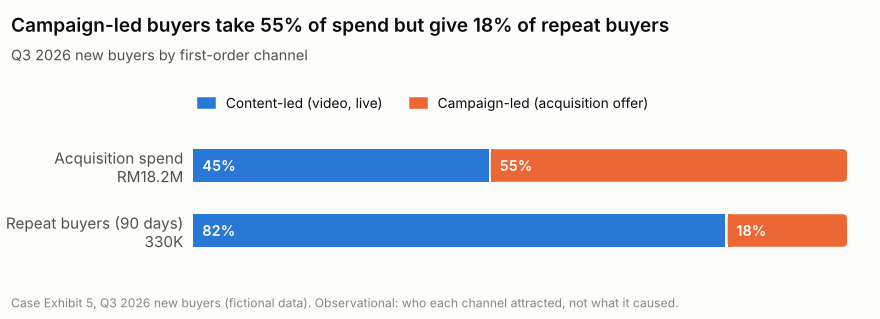

In [11]:
rows = [("Acquisition spend", "share_of_spend", f"RM{ch['spend_rm_m'].sum():.1f}M"),
        ("Repeat buyers (90 days)", "share_of_repeat_buyers", f"{ch['repeat_buyers_m'].sum()*1000:.0f}K")]
fig, ax = new_chart("Campaign-led buyers take 55% of spend but give 18% of repeat buyers",
                    "Q3 2026 new buyers by first-order channel", height=2.9, left=1.75, right=0.3, top=1.15, bottom=0.45)
ax.set_xlim(0, 1); ax.set_ylim(-0.6, 1.6)
ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False); ax.set_xticks([])
gap = 2 / ax.get_window_extent().width                  # 2px surface gap between segments
for i, (label, col, total) in enumerate(rows):
    y = 1 - i
    content, campaign = ch.loc["Content-led", col], ch.loc["Campaign-led", col]
    hbar(ax, y, content - gap / 2, height=0.5, color=BLUE, round_end=False)
    hbar(ax, y, campaign - gap / 2, left=content + gap / 2, height=0.5, color=ORANGE)
    ax.text(0.015, y, f"{content:.0%}", va="center", fontsize=9.5, color="white", fontweight="semibold")
    ax.text(content + 0.015, y, f"{campaign:.0%}", va="center", fontsize=9.5, color="white", fontweight="semibold")
ax.set_yticks([1, 0], [f"{r[0]}\n{r[2]}" for r in rows])
ax.tick_params(axis="y", colors=INK2)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE, label="Content-led (video, live)"),
                   plt.Rectangle((0, 0), 1, 1, color=ORANGE, label="Campaign-led (acquisition offer)")],
          loc="lower left", bbox_to_anchor=(-0.01, 1.02), ncol=2, fontsize=9, handlelength=1.2)
note(fig, "Case Exhibit 5, Q3 2026 new buyers (fictional data). Observational: who each channel attracted, not what it caused.")
save(fig, "my_spend_vs_repeat"); plt.show()

### 2.2 Sizing the 41+ pilot ("Mak") `C → D`, `M`

The 41+ segment has the biggest basket (RM39) and the fewest orders a year (44 vs 56 for 31–40 year olds). If those buyers closed half that gap, the value is large; and reaching new parents through their children (content-led, RM31 per repeat buyer) is far cheaper than buying them with campaign offers (RM163).

In [12]:
# Exhibit 4: buyers by age band, 2026 [C]
age = pd.DataFrame({"buyer_share": [.16, .24, .25, .23, .12], "gmv_share": [.11, .20, .27, .29, .13],
                    "aov_rm": [17, 22, 28, 36, 39], "orders_per_buyer": [65, 61, 60, 56, 44],
                    "repeat_90d": [.31, .42, .47, .50, .38]},
                   index=["18-21", "22-25", "26-30", "31-40", "41+"])
segments = {"Scouts 18-25 (channel)": ["18-21", "22-25"], "Builders 26-40 (protect)": ["26-30", "31-40"],
            "Anchors 41+ (pilot)": ["41+"]}
display(pd.DataFrame({name: {"buyer_share": age.loc[bands, "buyer_share"].sum(),
                             "gmv_share": age.loc[bands, "gmv_share"].sum(),
                             "basket_rm": "-".join(str(age.loc[b, "aov_rm"]) for b in (bands[0], bands[-1])),
                             "orders_per_buyer": "-".join(str(age.loc[b, "orders_per_buyer"]) for b in (bands[-1], bands[0]))}
                      for name, bands in segments.items()}).T)

BUYERS, GMV_RM = 6.2e6, 9.70e9
anchors = BUYERS * age.loc["41+", "buyer_share"]                                                  # [D]
extra_orders = (age.loc["31-40", "orders_per_buyer"] - age.loc["41+", "orders_per_buyer"]) / 2   # half the gap [M]
value_gap = anchors * extra_orders * age.loc["41+", "aov_rm"]                                    # [D]
scouts = BUYERS * age.loc[["18-21", "22-25"], "buyer_share"].sum()                               # [D]
new_parents = [scouts * a for a in (0.05, 0.10)]                    # 5-10% of Scouts bring a parent [M]
saving = [n * (163 - 31) for n in new_parents]                      # content-led instead of campaign-led [D]
gmv_per_anchor = GMV_RM * age.loc["41+", "gmv_share"] / anchors     # annual GMV per 41+ buyer [D]
year1 = [value_gap * 5/12 * cap + n * gmv_per_anchor * 2.5/12      # scale from month 8 [M]
         for cap, n in zip((0.5, 1.0), new_parents)]
platform_return = 0.085 * 3.6     # take rate x best incremental GMV per RM1 of trial subsidy [C, Exh. 2 and 9]

check("Malaysia", "Buyers aged 41+ (thousand)", 744, anchors / 1e3, 0.5)
check("Malaysia", "Value gap, 41+ (RM M a year)", 174, value_gap / 1e6, 0.5)
check("Malaysia", "Scouts aged 18-25 (M)", 2.48, scouts / 1e6, 0.005)
check("Malaysia", "New parents, low case (thousand)", 124, new_parents[0] / 1e3, 0.5)
check("Malaysia", "New parents, high case (thousand)", 248, new_parents[1] / 1e3, 0.5)
check("Malaysia", "Acquisition saving, low (RM M)", 16, saving[0] / 1e6, 0.5)
check("Malaysia", "Acquisition saving, high (RM M)", 33, saving[1] / 1e6, 0.5)
check("Malaysia", "Annual GMV per 41+ buyer (RM)", 1_695, gmv_per_anchor, 1)
check("Malaysia", "Year-1 scenario, low (RM M)", 80, year1[0] / 1e6, 0.5)
check("Malaysia", "Year-1 scenario, high (RM M)", 160, year1[1] / 1e6, 0.5)
check("Malaysia", "Platform return per RM1 of subsidy (RM)", 0.31, platform_return, 0.005)

✓ Buyers aged 41+ (thousand)                     deck    744.0   recomputed    744.0
✓ Value gap, 41+ (RM M a year)                   deck    174.0   recomputed    174.1
✓ Scouts aged 18-25 (M)                          deck     2.48   recomputed     2.48
✓ New parents, low case (thousand)               deck    124.0   recomputed    124.0
✓ New parents, high case (thousand)              deck    248.0   recomputed    248.0
✓ Acquisition saving, low (RM M)                 deck     16.0   recomputed     16.4
✓ Acquisition saving, high (RM M)                deck     33.0   recomputed     32.7
✓ Annual GMV per 41+ buyer (RM)                  deck    1,695   recomputed    1,695
✓ Year-1 scenario, low (RM M)                    deck     80.0   recomputed     80.1
✓ Year-1 scenario, high (RM M)                   deck    160.0   recomputed    160.1
✓ Platform return per RM1 of subsidy (RM)        deck    0.310   recomputed    0.306


,buyer_share,gmv_share,basket_rm,orders_per_buyer
Scouts 18-25 (channel),0.4,0.31,17-22,61-65
Builders 26-40 (protect),0.48,0.56,28-36,56-60
Anchors 41+ (pilot),0.12,0.13,39-39,44-44


### 2.3 Sensitivity (post-submission): how wide is the year-1 range? `M`

The year-1 scenario rests on two assumptions: how many Scouts bring a parent (activation) and how much of the 41+ order gap closes (capture). The grid shows year-1 GMV in RM million.

In [13]:
grid = pd.DataFrame({f"{c:.0%} capture": {f"{a*100:g}% of Scouts": (value_gap * 5/12 * c + scouts * a * gmv_per_anchor * 2.5/12) / 1e6
                                           for a in (0.05, 0.075, 0.10)}
                     for c in (0.50, 0.75, 1.00)})
display(grid.round(0))

,50% capture,75% capture,100% capture
5% of Scouts,80.0,98.0,116.0
7.5% of Scouts,102.0,120.0,138.0
10% of Scouts,124.0,142.0,160.0


Every cell clears RM80M, so the pilot is worth running even at the low end; the spread (RM80–160M) is why the deck calls it an illustrative scenario, not a forecast. One more caveat worth saying out loud in a review: Exhibit 5 is observational, so the RM31 vs RM163 gap shows who each channel attracted, not what it caused. That is why the plan moves money only behind the three-arm test: **scale** at ≥ 8 parent first orders per 100 Scouts, ≥ 45% 90-day repeat and ≤ RM20 cost; **stop** below 5, below 40% or above RM31.

## 3 · Thailand: Rising Stars 300 for 11.11

**The brief.** Hit +50% GMV against the prior mega campaign when top creators are about 50% sold out four weeks ahead and most sellers can't get a slot.
**Our answer.** Keep the top's half, and give the best 300 mid-tier creators the top's terms (vouchers, co-funding, feed priority) so that each sells half what a top creator does. Brands find them in their own For You feed.

### 3.1 How hard does each tier's traffic work? `C → D`

In [14]:
# Case Table 1 (Thailand): creator tiers by traffic share [C]
tiers = pd.DataFrame({"creators": [100, 900, 9_000], "traffic_share": [.40, .35, .25], "gmv_share": [.50, .35, .15],
                      "has_campaign_deal": ["~50% sold out", "~30%", "~20% attractive"]},
                     index=["Top 1%", "Mid (next 9%)", "Long tail (90%)"])
tiers["gmv_per_traffic_point"] = tiers["gmv_share"] / tiers["traffic_share"]       # [D]
tiers["gmv_per_creator"] = tiers["gmv_share"] * 100 / tiers["creators"]            # prior campaign = 100 [D]
display(tiers.round(3))

for k, deck in zip(tiers.index, [1.25, 1.00, 0.60]):
    check("Thailand", f"GMV per traffic point, {k}", deck, tiers.loc[k, "gmv_per_traffic_point"], 0.005)
top_each, mid_each = tiers.loc["Top 1%", "gmv_per_creator"], tiers.loc["Mid (next 9%)", "gmv_per_creator"]
check("Thailand", "A mid creator sells 1/x of a top (x)", 13, top_each / mid_each, 0.2)

✓ GMV per traffic point, Top 1%                  deck     1.25   recomputed     1.25
✓ GMV per traffic point, Mid (next 9%)           deck     1.00   recomputed     1.00
✓ GMV per traffic point, Long tail (90%)         deck    0.600   recomputed    0.600
✓ A mid creator sells 1/x of a top (x)           deck     13.0   recomputed     12.9


,creators,traffic_share,gmv_share,has_campaign_deal,gmv_per_traffic_point,gmv_per_creator
Top 1%,100,0.40,0.50,~50% sold out,1.25,0.500
Mid (next 9%),900,0.35,0.35,~30%,1.00,0.039
Long tail (90%),9000,0.25,0.15,~20% attractive,0.60,0.002


Mid-tier traffic sells at 80% of the top's rate (1.00 vs 1.25) and well above the long tail (0.60), yet only ~30% of mid creators have a campaign deal. That is the supply we can still buy for 11.11.

### 3.2 Same treatment as the top: budget per creator `C → D`

In [15]:
def budget_index(share, n_creators):        # a top creator today = 100 [D]
    return (share / n_creators) / (0.50 / 100) * 100

print(f"Top creator {budget_index(.50, 100):.0f} · mid/tail creator today {budget_index(.50, 9_900):.2f} · "
      f"Rising Star (plan) {budget_index(.25, 300):.1f} · everyone else (plan) {budget_index(.25, 9_600):.2f}\n")
check("Thailand", "Budget per creator today, mid and tail", 1.0, budget_index(.50, 9_900), 0.05)
check("Thailand", "Budget per creator, Rising Star (plan)", 17, budget_index(.25, 300), 0.4)
check("Thailand", "Budget per creator, everyone else (plan)", 0.5, budget_index(.25, 9_600), 0.05)

Top creator 100 · mid/tail creator today 1.01 · Rising Star (plan) 16.7 · everyone else (plan) 0.52

✓ Budget per creator today, mid and tail         deck     1.00   recomputed     1.01
✓ Budget per creator, Rising Star (plan)         deck     17.0   recomputed     16.7
✓ Budget per creator, everyone else (plan)       deck    0.500   recomputed    0.521


### 3.3 Why 300, and how 11.11 adds up to 150 `D`, `M`

In [16]:
TARGET_IDX, TOP_HOLD = 150, 50          # +50% target [C]; anchor contract keeps the top flat [M]
half_a_top = top_each / 2               # 0.25 index points per Rising Star [M]
floor = 70 / half_a_top                 # mid must go 35 -> 70; at half a top each [D]
on_time_pool = 900 * 0.50               # half of mid and tail lives start on time [C]
rising = 300 * half_a_top               # [D]
EVERYONE_ELSE = 25                      # 600 mid + 9,000 tail on half their budget per creator [M]
rest_today = {m: 50 - 300 * mid_each * m for m in (1.05, 1.10, 1.20)}   # best 300 sell 1.05-1.20x the mid average [M]

check("Thailand", "Other half must grow (%)", 100, (TARGET_IDX - TOP_HOLD) / 50 * 100 - 100, 0.01)
check("Thailand", "Floor: creators needed at half a top", 280, floor, 0.01)
check("Thailand", "On-time pool to choose from", 450, on_time_pool, 0.01)
check("Thailand", "Rising Stars' GMV (index points)", 75, rising, 0.01)
check("Thailand", "11.11 bridge: 50 + 75 + 25", 150, TOP_HOLD + rising + EVERYONE_ELSE, 0.01)
check("Thailand", "Everyone else today (index, at 1.10x)", 38, rest_today[1.10], 1.0)
print(f"\nEveryone else today across the 1.05-1.20x rank assumption: "
      + ", ".join(f"{v:.1f} at {m:.2f}x" for m, v in rest_today.items()))

✓ Other half must grow (%)                       deck    100.0   recomputed    100.0
✓ Floor: creators needed at half a top           deck    280.0   recomputed    280.0
✓ On-time pool to choose from                    deck    450.0   recomputed    450.0
✓ Rising Stars' GMV (index points)               deck     75.0   recomputed     75.0
✓ 11.11 bridge: 50 + 75 + 25                     deck    150.0   recomputed    150.0
✓ Everyone else today (index, at 1.10x)          deck     38.0   recomputed     37.2

Everyone else today across the 1.05-1.20x rank assumption: 37.8 at 1.05x, 37.2 at 1.10x, 36.0 at 1.20x


### 3.4 Stress test (post-submission): what must each Rising Star sell? `M`

The whole plan rests on the *half-a-top* hypothesis. Here 11.11 GMV is recomputed for any level of Rising Star sales, in two worlds: the 9,600 other creators fall to 25 on half their budget (the deck's assumption), or they hold today's ~37.

In [17]:
best_today = mid_each * 1.10 / top_each          # best 300 today, as a share of a top creator [M]

def gmv_1111(k, rest):                           # k = Rising Star sales as a share of a top creator
    return TOP_HOLD + 300 * top_each * k + rest

for rest, label in [(EVERYONE_ELSE, "rest fall to 25 (deck)"), (rest_today[1.10], "rest hold today's ~37")]:
    breakeven = (TARGET_IDX - TOP_HOLD - rest) / (300 * top_each)
    print(f"{label:<24} break-even: {breakeven:.2f} of a top · 11.11 with no lift: {gmv_1111(best_today, rest):.0f}")
print(f"\nToday the best 300 sell {best_today:.3f} of a top creator, so 'half a top' is a {0.5 / best_today:.1f}x lift "
      f"per creator, backed by {budget_index(.25, 300) / budget_index(.50, 9_900):.0f}x the budget per creator.")

rest fall to 25 (deck)   break-even: 0.50 of a top · 11.11 with no lift: 88
rest hold today's ~37    break-even: 0.42 of a top · 11.11 with no lift: 100

Today the best 300 sell 0.086 of a top creator, so 'half a top' is a 5.8x lift per creator, backed by 17x the budget per creator.


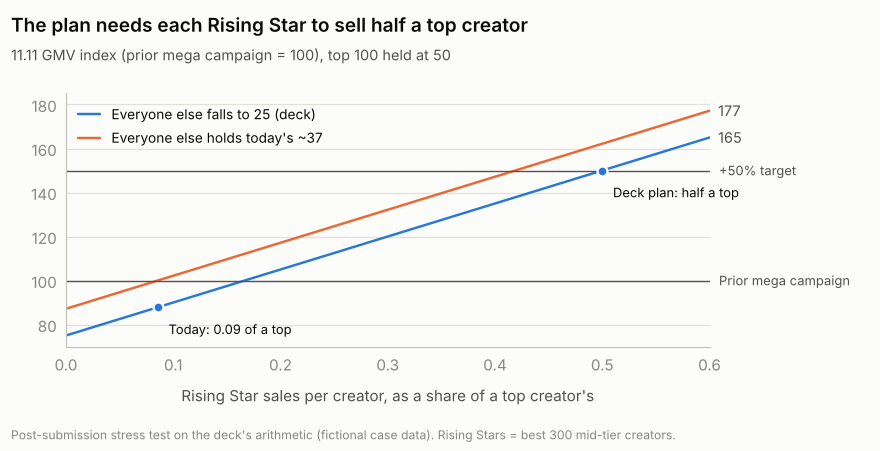

In [18]:
ks = [i / 100 for i in range(0, 61)]
fig, ax = new_chart("The plan needs each Rising Star to sell half a top creator",
                    "11.11 GMV index (prior mega campaign = 100), top 100 held at 50",
                    height=4.1, left=0.6, right=1.55, bottom=0.95)
ax.set_xlim(0, 0.6); ax.set_ylim(70, 185)
ax.yaxis.grid(True); ax.set_axisbelow(True)
for rest, color, label in [(EVERYONE_ELSE, BLUE, "Everyone else falls to 25 (deck)"),
                           (rest_today[1.10], ORANGE, "Everyone else holds today's ~37")]:
    ys = [gmv_1111(k, rest) for k in ks]
    ax.plot(ks, ys, color=color, lw=1.6, solid_capstyle="round", label=label)
    ax.text(ks[-1] + 0.008, ys[-1], f"{ys[-1]:.0f}", va="center", fontsize=9.5, color=INK2)
for level, text in [(150, "+50% target"), (100, "Prior mega campaign")]:
    ax.axhline(level, color=INK2, lw=0.9)
    ax.text(0.602, level, f"  {text}", va="center", fontsize=8.5, color=INK2, transform=ax.transData, clip_on=False)
for k, text, dy in [(best_today, f"Today: {best_today:.2f} of a top", -10), (0.5, "Deck plan: half a top", -10)]:
    y = gmv_1111(k, EVERYONE_ELSE)
    ax.plot(k, y, "o", ms=6.5, color=BLUE, mec=SURFACE, mew=1.5, zorder=5)
    ax.text(k + 0.01, y + dy, text, fontsize=8.5, color=INK, va="center")
ax.legend(loc="upper left", fontsize=9, handlelength=1.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1f}")
ax.set_xlabel("Rising Star sales per creator, as a share of a top creator's", labelpad=8)
note(fig, "Post-submission stress test on the deck's arithmetic (fictional case data). Rising Stars = best 300 mid-tier creators.")
save(fig, "th_rising_star_stress"); plt.show()

The honest read: the plan needs a big per-creator lift, and it has a downside. If the lift doesn't come and everyone else falls to 25, 11.11 lands **below** the prior campaign. The deck manages this with dated checkpoints rather than hope: 85% of Rising Star slots booked by 4 November (otherwise bench creators fill the niche), lives on time, and a scorecard read in the tools sellers already use. What I would add with hindsight is an explicit reversal rule: if bookings miss on 4 November, hand the long tail its budget back before 11.11.

## 4 · Audit summary

In [19]:
audit = pd.DataFrame(AUDIT)
print(f"{(audit['match'] == 'yes').sum()} of {len(audit)} deck figures reproduced within rounding")
display(audit.groupby("market", sort=False)["match"].value_counts().unstack(fill_value=0))

50 of 50 deck figures reproduced within rounding


match,yes
market,
Vietnam,17
Malaysia,20
Thailand,13


## 5 · What I would do with real data

| Market | Case-stage shortcut | With platform data |
|---|---|---|
| Vietnam | Straight-line hourly pass mark | Fit the hourly GMV shape from the 11.11 rehearsal (views, orders per 1,000 views, AOV by hour) and set a shaped pass mark; alert on the weakest driver in SQL over the LIVE event table |
| Malaysia | Observational channel costs (Exhibit 5) | Read the three-arm pilot as an experiment: contribution per *assigned* Scout with confidence intervals, plus guardrails on disputes and unauthorised payments |
| Thailand | Best 300 assumed at 1.05–1.20× the mid average | Rank all 900 mid creators on actual GMV per traffic point and on-time rate, and back-test the half-a-top hypothesis on the prior campaign's cohorts |